# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170001         # <-- your full roll number
NAME = "Krishna"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170018   Name: Sumit   Fingerprint: C7EEB66F   Tickets: 15

Ticket_ID                                                                               Ticket_Text
      T01               I couldn't connect to the VPN when I use mobile hotspot. Please resolve it.
      T02                      Python is not working while uploading the file. It worked yesterday.
      T03                              I can't open the printer since yesterday. Please resolve it.
      T04                      I tried restarting the email when I use mobile hotspot. Please help.
      T05                                                               My roll no. is 1023-03-021.
      T06                                                    Only 2 of 30 PCs boot after 3.5 hours.
      T07                                                     It's not the laptop; it's the server.
      T08                               The password is running slowly. I have tried several times!
      T09              

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [40]:
import pandas as pd

results = []

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    ticket = row["Ticket_Text"]

    processed = process_ticket(ticket)


    sentences = processed["sentences"]
    tokens = processed["tokens"]
    punctuation_tokens = processed["punct"]
    stopword_tokens = processed["stops"]
    final_tokens = processed["final"]


    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(sentences),
        "Tokens": len(tokens),
        "Punctuation Tokens": len(punctuation_tokens),
        "Stopwords": len(stopword_tokens),
        "Unique Tokens": len(set(tokens)),
        "Final Tokens": len(final_tokens)
    })


results_df = pd.DataFrame(results)


count_columns = [
    "Sentences",
    "Tokens",
    "Punctuation Tokens",
    "Stopwords",
    "Unique Tokens",
    "Final Tokens"
]

total_row = {"Ticket_ID": "TOTAL"}

for col in count_columns:
    total_row[col] = results_df[col].sum()

results_df = pd.concat(
    [results_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(results_df)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,17,2,6,15,9
1,T02,2,13,2,5,12,6
2,T03,2,13,2,3,12,8
3,T04,2,14,2,4,12,8
4,T05,2,7,2,3,6,2
5,T06,1,10,1,3,10,6
6,T07,1,11,2,5,8,4
7,T08,2,12,2,4,12,6
8,T09,2,10,4,3,8,3
9,T10,2,15,2,5,14,8


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

Some final tokens, such as n't, 's, and ca, are fragments of contractions rather than complete words. They originate from the tokenization process, which splits contractions into separate tokens. For example, "couldn't" is split into "could" and "n't". These fragments remain in the final tokens because the preprocessing pipeline does not remove them

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [41]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re


long_words = [
    re.findall(r"(?<![A-Za-z'])\b[A-Za-z]{6,}\b(?![A-Za-z'])", ticket)
    for ticket in df["Ticket_Text"]
]


numbers = [
    re.findall(r"\b\d+(?:\.\d+)*\b", ticket)
    for ticket in df["Ticket_Text"]
]


capitalized_words = [
    re.findall(r"\b[A-Z][a-zA-Z]*\b", ticket)
    for ticket in df["Ticket_Text"]
]


vowel_words = [
    re.findall(r"\b[aeiou][a-z]*\b", ticket, re.IGNORECASE)
    for ticket in df["Ticket_Text"]
]


for i, ticket in enumerate(df["Ticket_Text"]):
    print(f"\n{df.iloc[i]['Ticket_ID']}: {ticket}")
    print("Long words:", long_words[i])
    print("Numbers:", numbers[i])
    print("Capitalized words:", capitalized_words[i])
    print("Words beginning with vowels:", vowel_words[i])



email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"

phone_pattern = r"(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4,5}-\d{3,5}-\d{2,5})(?!\w)"


def replace_patterns(text):
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text



print("\n========== TEST_LINES ==========")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Replaced:", replace_patterns(line))


T01: I couldn't connect to the VPN when I use mobile hotspot. Please resolve it.
Long words: ['connect', 'mobile', 'hotspot', 'Please', 'resolve']
Numbers: []
Capitalized words: ['I', 'VPN', 'I', 'Please']
Words beginning with vowels: ['I', 'I', 'use', 'it']

T02: Python is not working while uploading the file. It worked yesterday.
Long words: ['Python', 'working', 'uploading', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['Python', 'It']
Words beginning with vowels: ['is', 'uploading', 'It']

T03: I can't open the printer since yesterday. Please resolve it.
Long words: ['printer', 'yesterday', 'Please', 'resolve']
Numbers: []
Capitalized words: ['I', 'Please']
Words beginning with vowels: ['I', 'open', 'it']

T04: I tried restarting the email when I use mobile hotspot. Please help.
Long words: ['restarting', 'mobile', 'hotspot', 'Please']
Numbers: []
Capitalized words: ['I', 'I', 'Please']
Words beginning with vowels: ['I', 'email', 'I', 'use']

T05: My roll no. is 1023-03-0

In [42]:
import re

for _, row in df.iterrows():
    sentences = re.split(r'(?<=[.!?])\s+', row["Ticket_Text"])

    initial_words = []

    for sentence in sentences:
        match = re.match(r"\s*([A-Z][A-Za-z]*)", sentence)

        if match:
            initial_words.append(match.group(1))

    print(row["Ticket_ID"], initial_words)

T01 ['I', 'Please']
T02 ['Python', 'It']
T03 ['I', 'Please']
T04 ['I', 'Please']
T05 ['My']
T06 ['Only']
T07 ['It']
T08 ['The', 'I']
T09 ['I']
T10 ['I', 'Please']
T11 ['Student', 'It']
T12 ['I', 'I']
T13 ['The', 'Can']
T14 ['I', 'This']
T15 ['Printer', 'It']


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

Many capitalized words in the dataset are capitalized because they occur at the beginning of a sentence. Examples include "Please", "The", "My", and "Can". However, some words, such as "Python", are capitalized because they are technical names, while "I" is always capitalized in English. Therefore, not every sentence-initial capitalized word is capitalized solely because of its position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [43]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://[^\s<>\[\]()]+"
    r"|www\.[^\s<>\[\]()]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|(?:\+91[\s-]?)?\d{5}[\s-]\d{5}"
    r"|\d{4,5}-\d{3,5}-\d{2,5}"
    r"|\d+(?:\.\d+)+"
    r"|[A-Za-z]+(?:[-'][A-Za-z]+)*"
    r"|\d[\d,]*"
    r"|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)


def my_tokenize(text):

    text = re.sub(
        r'\[([^\]]+)\]\(([^)]+)\)',
        r'\2',
        text
    )


    text = re.sub(r'\bmailto:', '', text)

    return tokenizer.tokenize(text)



print("========== TEST_LINES ==========")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Custom tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))


print("\n========== GENERATED TICKETS ==========")

for _, row in df.iterrows():
    ticket = row["Ticket_Text"]

    print(f"\n{row['Ticket_ID']}: {ticket}")
    print("Custom tokenizer:", my_tokenize(ticket))
    print("word_tokenize:", word_tokenize(ticket))


different_tickets = []

for _, row in df.iterrows():
    ticket = row["Ticket_Text"]

    custom_tokens = my_tokenize(ticket)
    standard_tokens = word_tokenize(ticket)

    if custom_tokens != standard_tokens:
        different_tickets.append(row["Ticket_ID"])


print("\n========== COMPARISON SUMMARY ==========")
print("Total tickets:", len(df))
print("Tickets tokenized differently:", len(different_tickets))
print("Ticket IDs:", different_tickets)

========== TEST_LINES ==========

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

The custom tokenizer and word_tokenize() produce different results for contractions, punctuation and identifiers. For example, the custom tokenizer preserves "couldn't" as one token, whereas word_tokenize() splits it into "could" and "n't". The custom tokenizer also splits repeated full stops individually, while word_tokenize() preserves "..." as one token. Additionally, the two tokenizers handle hyphenated identifiers differently.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [44]:
# Your code
import re
import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.tokenize import word_tokenize

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r'ing$|ed$|s$', min=4)
lemmatizer = WordNetLemmatizer()


unique_final_tokens = set()

for ticket in df["Ticket_Text"]:
    processed = process_ticket(ticket)
    unique_final_tokens.update(processed["final"])


def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'  # Adjective
    elif tag.startswith('V'):
        return 'v'  # Verb
    elif tag.startswith('N'):
        return 'n'  # Noun
    elif tag.startswith('R'):
        return 'r'  # Adverb
    else:
        return 'n'  # noun


words = sorted(unique_final_tokens)
tagged_words = pos_tag(words)

results = []

for word, tag in tagged_words:
    wordnet_pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=wordnet_pos)

    results.append({
        "Word": word,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp": regexp_result,
        "WordNet Lemma": lemma_result
    })


comparison_df = pd.DataFrame(results)


different_df = comparison_df[
    comparison_df[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]]
    .nunique(axis=1) > 1
].reset_index(drop=True)

display(different_df)

,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,computer,comput,comput,computer,computer
3,deadline,deadlin,deadlin,deadline,deadline
4,file,file,fil,file,file
5,mobile,mobil,mobl,mobile,mobile
6,open,open,op,open,open
7,pcs,pc,pcs,pcs,pcs
8,please,pleas,pleas,please,please
9,portal,portal,port,portal,portal


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

Over-stemming: The Lancaster Stemmer converts "student" into "stud". This removes too much of the original word and makes the resulting stem less recognizable.

Under-stemming: The Porter Stemmer may leave related words with different stems when it fails to reduce their forms to a common stem. This can prevent related words from being grouped together.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

========== CORPUS STATISTICS ==========

S1: All tokens
Total tokens: 193
Unique tokens: 82
TTR: 0.4249

S2: No punctuation
Total tokens: 162
Unique tokens: 77
TTR: 0.4753

S3: Final tokens
Total tokens: 96
Unique tokens: 56
TTR: 0.5833

S4: Porter stemmed tokens
Total tokens: 96
Unique tokens: 54
TTR: 0.5625

========== TOP 10 WORDS ==========

S1:
[('.', 23), ('the', 14), ('i', 12), ('it', 8), ('!', 5), ("n't", 4), ('please', 4), ('is', 4), ('yesterday', 4), ('open', 4)]

S3:
[("n't", 4), ('please', 4), ('yesterday', 4), ('open', 4), ('tried', 4), ('use', 3), ('mobile', 3), ('hotspot', 3), ('resolve', 3), ('ca', 3)]

========== ZIPF PLOT ==========


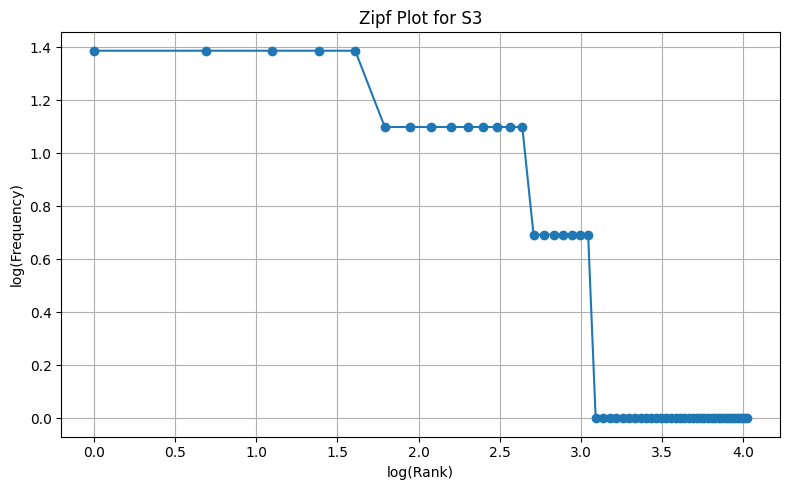


========== TOP 5 BIGRAMS ==========

S1:
[(('.', 'i'), 5), (('.', 'please'), 4), (('.', 'it'), 4), (('when', 'i'), 3), (('i', 'use'), 3)]

S3:
[(('use', 'mobile'), 3), (('mobile', 'hotspot'), 3), (('please', 'resolve'), 3), (('ca', "n't"), 3), (("n't", 'open'), 3)]


In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import string

from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams


S1 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)
    S1.extend(result["tokens"])


S2 = [
    token for token in S1
    if not all(char in string.punctuation for char in token)
]


S3 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)
    S3.extend(result["final"])


porter = PorterStemmer()
S4 = [porter.stem(word) for word in S3]


def corpus_stats(name, tokens):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    ttr = unique_tokens / total_tokens if total_tokens else 0

    print(f"\n{name}")
    print("Total tokens:", total_tokens)
    print("Unique tokens:", unique_tokens)
    print(f"TTR: {ttr:.4f}")


print("========== CORPUS STATISTICS ==========")

corpus_stats("S1: All tokens", S1)
corpus_stats("S2: No punctuation", S2)
corpus_stats("S3: Final tokens", S3)
corpus_stats("S4: Porter stemmed tokens", S4)


print("\n========== TOP 10 WORDS ==========")

print("\nS1:")
print(Counter(S1).most_common(10))

print("\nS3:")
print(Counter(S3).most_common(10))


print("\n========== ZIPF PLOT ==========")

frequency = Counter(S3)
sorted_freq = sorted(frequency.values(), reverse=True)

ranks = np.arange(1, len(sorted_freq) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(sorted_freq), marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.tight_layout()
plt.show()


print("\n========== TOP 5 BIGRAMS ==========")

print("\nS1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nS3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

The Type-Token Ratio changes as preprocessing modifies the corpus. From S1 to S2, removing punctuation reduces the total number of tokens from 193 to 162 and the number of unique tokens from 82 to 77. Consequently, TTR increases from 0.4249 to 0.4753. From S2 to S3, further preprocessing reduces the corpus to 96 tokens and 56 unique tokens, increasing TTR to 0.5833. Finally, Porter stemming leaves the total number of tokens unchanged at 96 but reduces the number of unique tokens to 54, lowering TTR to 0.5625. Stemming combines some word forms under common stems, reducing vocabulary diversity.

Q6
(a) Answered above

(b)Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
ans-For the word "couldn't", my custom tokenizer produces ["couldn't"], whereas word_tokenize() produces ["could", "n't"]. The custom tokenizer preserves the contraction as a single token, while the standard tokenizer splits it into two tokens.

(c)Give one example where stemming produces an undesirable result.
ans-The Lancaster Stemmer converts "student" into "stud". This is undesirable because it removes too much of the original word, making the resulting stem less recognizable.

(d)Give one example where POS-aware lemmatization preserves meaning better than stemming.
ans-For the word "tried", the Porter Stemmer produces "tri", whereas the POS-aware WordNet Lemmatizer produces "try". The lemma "try" is a recognizable dictionary word that preserves the intended meaning better than the stem "tri".